# 刘群 38720260158062
第7讲核心任务可复现实验。对应2026-10-21新版工作单；测试标签已获准释放。先固定方案，再打开测试标签。不执行另需冻结的换目标拓展。

## A 数据与职责

In [1]:
from pathlib import Path
import sys, json
import numpy as np, pandas as pd
BASE=next(p for p in [Path.cwd()/'7. Naive-Bayes',Path.cwd().parent/'7. Naive-Bayes'] if (p/'scripts/lab_utils.py').exists())
sys.path.insert(0,str(BASE/'scripts'))
from lab_utils import *
train=pd.read_csv(BASE/'data/student/train.csv')
val=pd.read_csv(BASE/'data/student/validation.csv')
print('特征',FEATURES)
for name,f in [('train',train),('validation',val)]:
 print(name,len(f),f.bladder_inflammation.value_counts().to_dict(),'缺失',f.isna().sum().sum())
assert not set(train.sample_id)&set(val.sample_id)
profiles=set(map(tuple,train[FEATURES].to_numpy()))
print('验证已见模式记录数',sum(tuple(x) in profiles for x in val[FEATURES].to_numpy()))


特征 ['fever_ge_38', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pain', 'burning_urethra']
train 72 {0: 37, 1: 35} 缺失 0
validation 24 {0: 12, 1: 12} 缺失 0
验证已见模式记录数 24


## A2 估参和后验手算

In [2]:
model=fit_model(train)
hand,weights,posterior=hand_calculation(train,[0,0,0,1,1,1])
print(hand.to_string(index=False));print('权重',weights,'后验',posterior)
program=model.predict_proba(pd.DataFrame([[0,0,0,1,1,1]],columns=FEATURES))[0,1]
print('手算与程序差',abs(program-posterior))
assert abs(program-posterior)<1e-12


 label  n_class          feature  x  count_one    theta  likelihood_term
     0       37      fever_ge_38  0         25 0.666667         0.333333
     0       37           nausea  0          5 0.153846         0.846154
     0       37      lumbar_pain  0         30 0.794872         0.205128
     0       37    urine_pushing  1         13 0.358974         0.358974
     0       37 micturition_pain  1          5 0.153846         0.153846
     0       37  burning_urethra  1         13 0.358974         0.358974
     1       35      fever_ge_38  0         13 0.378378         0.621622
     1       35           nausea  0         13 0.378378         0.621622
     1       35      lumbar_pain  0         13 0.378378         0.621622
     1       35    urine_pushing  1         35 0.972973         0.972973
     1       35 micturition_pain  1         28 0.783784         0.783784
     1       35  burning_urethra  1         17 0.486486         0.486486
权重 [0.00058944 0.04331933] 后验 0.9865759062601743
手算

## B 损失与阈值

In [3]:
p=model.predict_proba(val[FEATURES])[:,1]
for name,f,prob in [('train',train,model.predict_proba(train[FEATURES])[:,1]),('validation',val,p),('prior',val,np.full(len(val),train.bladder_inflammation.mean()))]:
 print(name,scores(f.bladder_inflammation,prob))
thresholds=threshold_table(val.bladder_inflammation,p)
chosen=choose_threshold(thresholds)
print(thresholds.to_string(index=False));print('选定阈值',chosen)
print('教学log loss',-np.log(.6),-np.log(.9),-np.log(.4),-np.log(.01))


train {'tn': 37, 'fp': 0, 'fn': 0, 'tp': 35, 'accuracy': 1.0, 'sensitivity': 1.0, 'specificity': 1.0, 'precision': 1.0, 'f1': 1.0, 'roc_auc': 1.0, 'average_precision': 1.0, 'brier': 0.016584080802948722, 'log_loss': 0.09884043265553948}
validation {'tn': 12, 'fp': 0, 'fn': 0, 'tp': 12, 'accuracy': 1.0, 'sensitivity': 1.0, 'specificity': 1.0, 'precision': 1.0, 'f1': 1.0, 'roc_auc': 1.0, 'average_precision': 1.0, 'brier': 0.011766036393776921, 'log_loss': 0.08721381083393166}
prior {'tn': 12, 'fp': 0, 'fn': 12, 'tp': 0, 'accuracy': 0.5, 'sensitivity': 0.0, 'specificity': 1.0, 'precision': nan, 'f1': 0.0, 'roc_auc': 0.5, 'average_precision': 0.5, 'brier': 0.2501929012345679, 'log_loss': 0.6935331319492363}
 threshold  tn  fp  fn  tp  accuracy  sensitivity  specificity  precision       f1  roc_auc  average_precision    brier  log_loss
      0.05   4   8   0  12  0.666667     1.000000     0.333333   0.600000 0.750000      1.0                1.0 0.011766  0.087214
      0.10   7   5   0  12 

## C 条件独立与概率质量

In [4]:
print(reliability(val.bladder_inflammation,p).to_string(index=False))
for copies in [0,1,5]:
 a=train[FEATURES].copy();b=val[FEATURES].copy()
 for i in range(copies):a[f'copy{i}']=a.lumbar_pain;b[f'copy{i}']=b.lumbar_pain
 m=BernoulliNB(alpha=1,binarize=None).fit(a,train.bladder_inflammation)
 pp=m.predict_proba(b)[:,1]
 print('额外腰痛副本',copies,scores(val.bladder_inflammation,pp))
 if copies==5:print(pd.DataFrame({'ID':val.sample_id,'原概率':p,'复制后':pp}).to_string(index=False))


          bin  n  mean_probability  observed_fraction
(-0.001, 0.2] 12          0.089002                0.0
   (0.2, 0.4]  0               NaN                NaN
   (0.4, 0.6]  0               NaN                NaN
   (0.6, 0.8]  1          0.685429                1.0
   (0.8, 1.0] 11          0.950279                1.0
额外腰痛副本 0 {'tn': 12, 'fp': 0, 'fn': 0, 'tp': 12, 'accuracy': 1.0, 'sensitivity': 1.0, 'specificity': 1.0, 'precision': 1.0, 'f1': 1.0, 'roc_auc': 1.0, 'average_precision': 1.0, 'brier': 0.011766036393776921, 'log_loss': 0.08721381083393166}
额外腰痛副本 1 {'tn': 12, 'fp': 0, 'fn': 0, 'tp': 12, 'accuracy': 1.0, 'sensitivity': 1.0, 'specificity': 1.0, 'precision': 1.0, 'f1': 1.0, 'roc_auc': 1.0, 'average_precision': 1.0, 'brier': 0.008387244211459003, 'log_loss': 0.07042546151290947}
额外腰痛副本 5 {'tn': 11, 'fp': 1, 'fn': 5, 'tp': 7, 'accuracy': 0.75, 'sensitivity': 0.5833333333333334, 'specificity': 0.9166666666666666, 'precision': 0.875, 'f1': 0.7, 'roc_auc': 0.9652777777777779,

## D1 固定方案

In [5]:
freeze=dict(name='刘群',student_id='38720260158062',target='bladder_inflammation',features=FEATURES,alpha=1,threshold=chosen,train_ids=train.sample_id.tolist(),date='2026-11-18',refit=False)
print(json.dumps(freeze,ensure_ascii=False,indent=2))
FREEZE_CONFIRMED=True
OPEN_LOCKED_TEST=True # 用户已确认教师允许最终评价


{
  "name": "刘群",
  "student_id": "38720260158062",
  "target": "bladder_inflammation",
  "features": [
    "fever_ge_38",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "burning_urethra"
  ],
  "alpha": 1,
  "threshold": 0.5,
  "train_ids": [
    "A114",
    "A012",
    "A073",
    "A108",
    "A086",
    "A005",
    "A056",
    "A042",
    "A039",
    "A087",
    "A076",
    "A017",
    "A068",
    "A089",
    "A044",
    "A002",
    "A118",
    "A003",
    "A120",
    "A061",
    "A074",
    "A055",
    "A013",
    "A116",
    "A026",
    "A033",
    "A095",
    "A011",
    "A046",
    "A119",
    "A037",
    "A020",
    "A112",
    "A092",
    "A050",
    "A075",
    "A031",
    "A115",
    "A060",
    "A079",
    "A111",
    "A014",
    "A004",
    "A078",
    "A029",
    "A098",
    "A001",
    "A028",
    "A027",
    "A085",
    "A067",
    "A097",
    "A099",
    "A025",
    "A051",
    "A062",
    "A070",
    "A084",
    "A105",
    "A082",
 

## D2 固定测试

In [6]:
assert FREEZE_CONFIRMED and OPEN_LOCKED_TEST
test=pd.read_csv(BASE/'data/student/locked-test-features.csv').merge(pd.read_csv(BASE/'data/teacher/locked-test-labels.csv'),on='sample_id',validate='one_to_one')
assert not set(test.sample_id)&(set(train.sample_id)|set(val.sample_id))
tp=model.predict_proba(test[FEATURES])[:,1]
print(scores(test.bladder_inflammation,tp,chosen))
print('已见模式记录数',sum(tuple(x) in profiles for x in test[FEATURES].to_numpy()))
print('测试不同模式数',len(test[FEATURES].drop_duplicates()))
print(pd.DataFrame({'ID':test.sample_id,'y':test.bladder_inflammation,'p':tp}).to_string(index=False))


{'tn': 12, 'fp': 0, 'fn': 0, 'tp': 12, 'accuracy': 1.0, 'sensitivity': 1.0, 'specificity': 1.0, 'precision': 1.0, 'f1': 1.0, 'roc_auc': 1.0, 'average_precision': 1.0, 'brier': 0.01264120822588853, 'log_loss': 0.07449229980495913}
已见模式记录数 24
测试不同模式数 8
  ID  y        p
A057  1 0.977499
A032  1 0.977499
A010  1 0.986576
A058  0 0.005296
A007  1 0.986576
A052  1 0.685429
A117  0 0.010210
A066  0 0.149824
A045  1 0.685429
A069  0 0.149824
A016  0 0.005296
A038  0 0.005296
A048  1 0.986576
A107  1 0.874262
A006  0 0.005296
A030  1 0.986576
A047  1 0.977499
A008  0 0.005296
A049  1 0.977499
A019  1 0.986576
A103  0 0.010210
A064  0 0.149824
A088  0 0.097602
A113  0 0.097602


### 图1（由build.py生成，与上述分析同源）

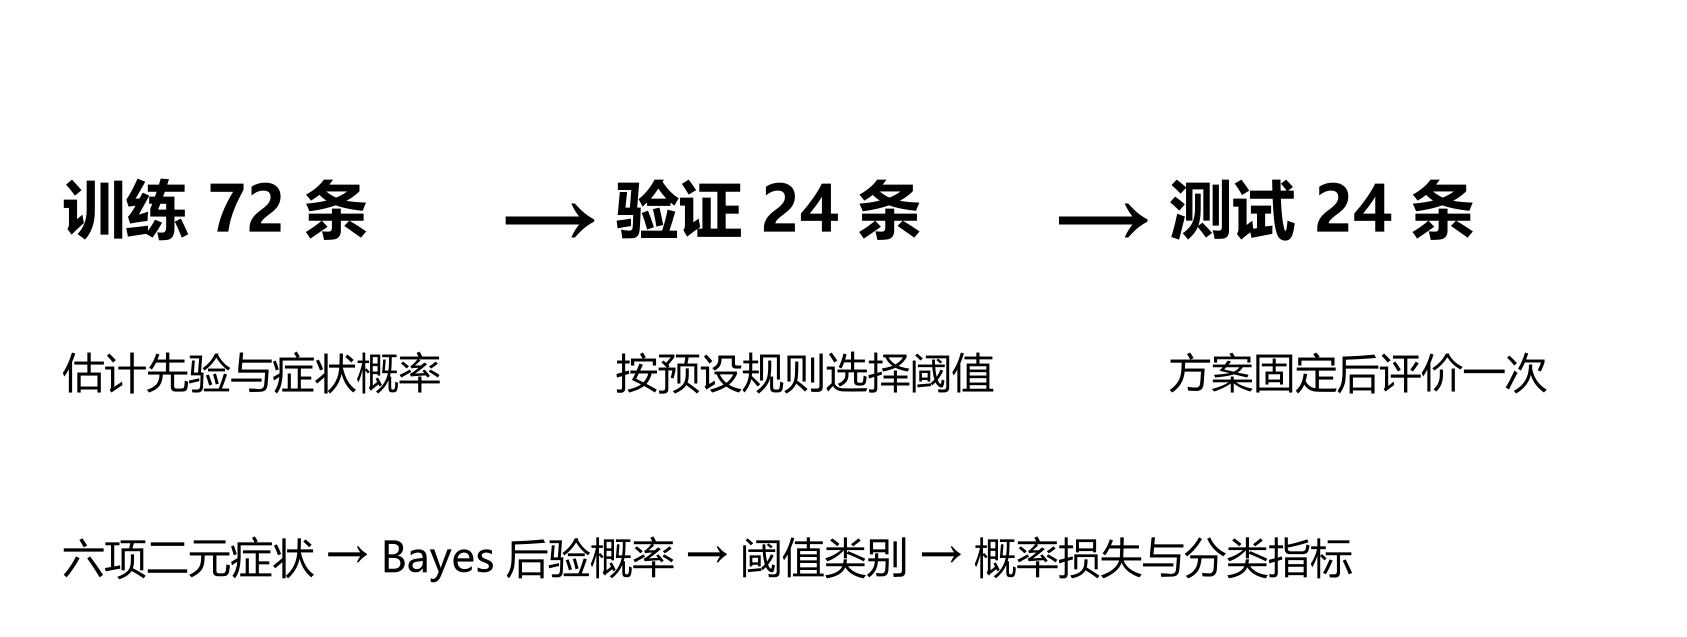

### 图2（由build.py生成，与上述分析同源）

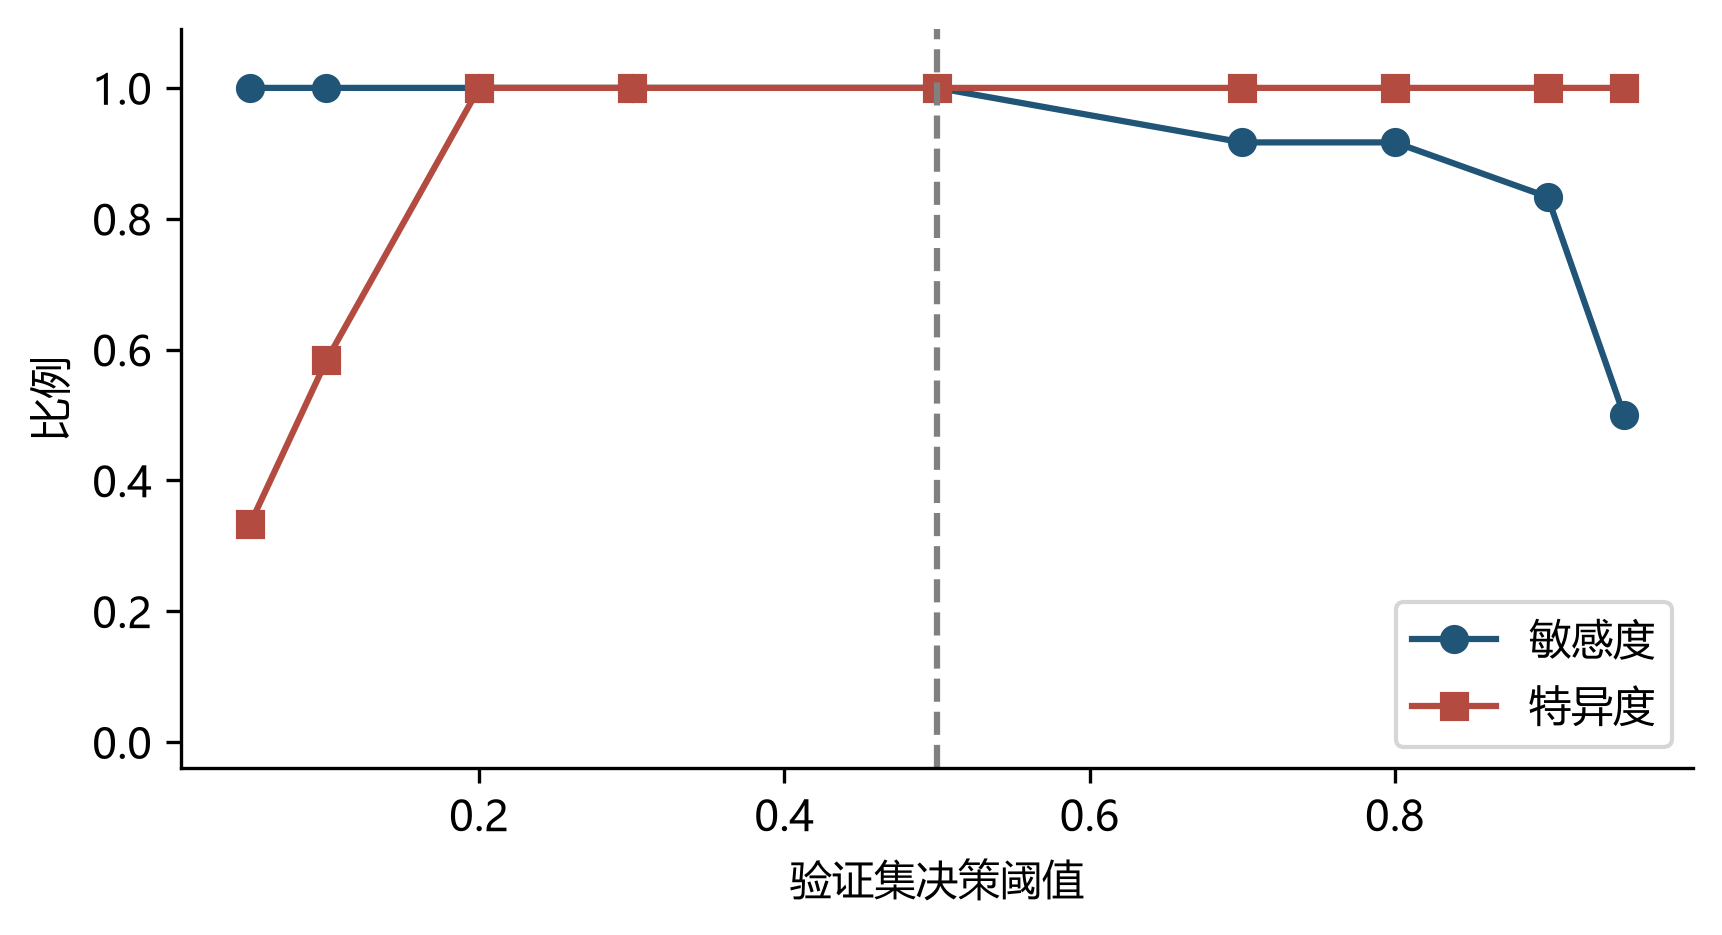

### 图3（由build.py生成，与上述分析同源）

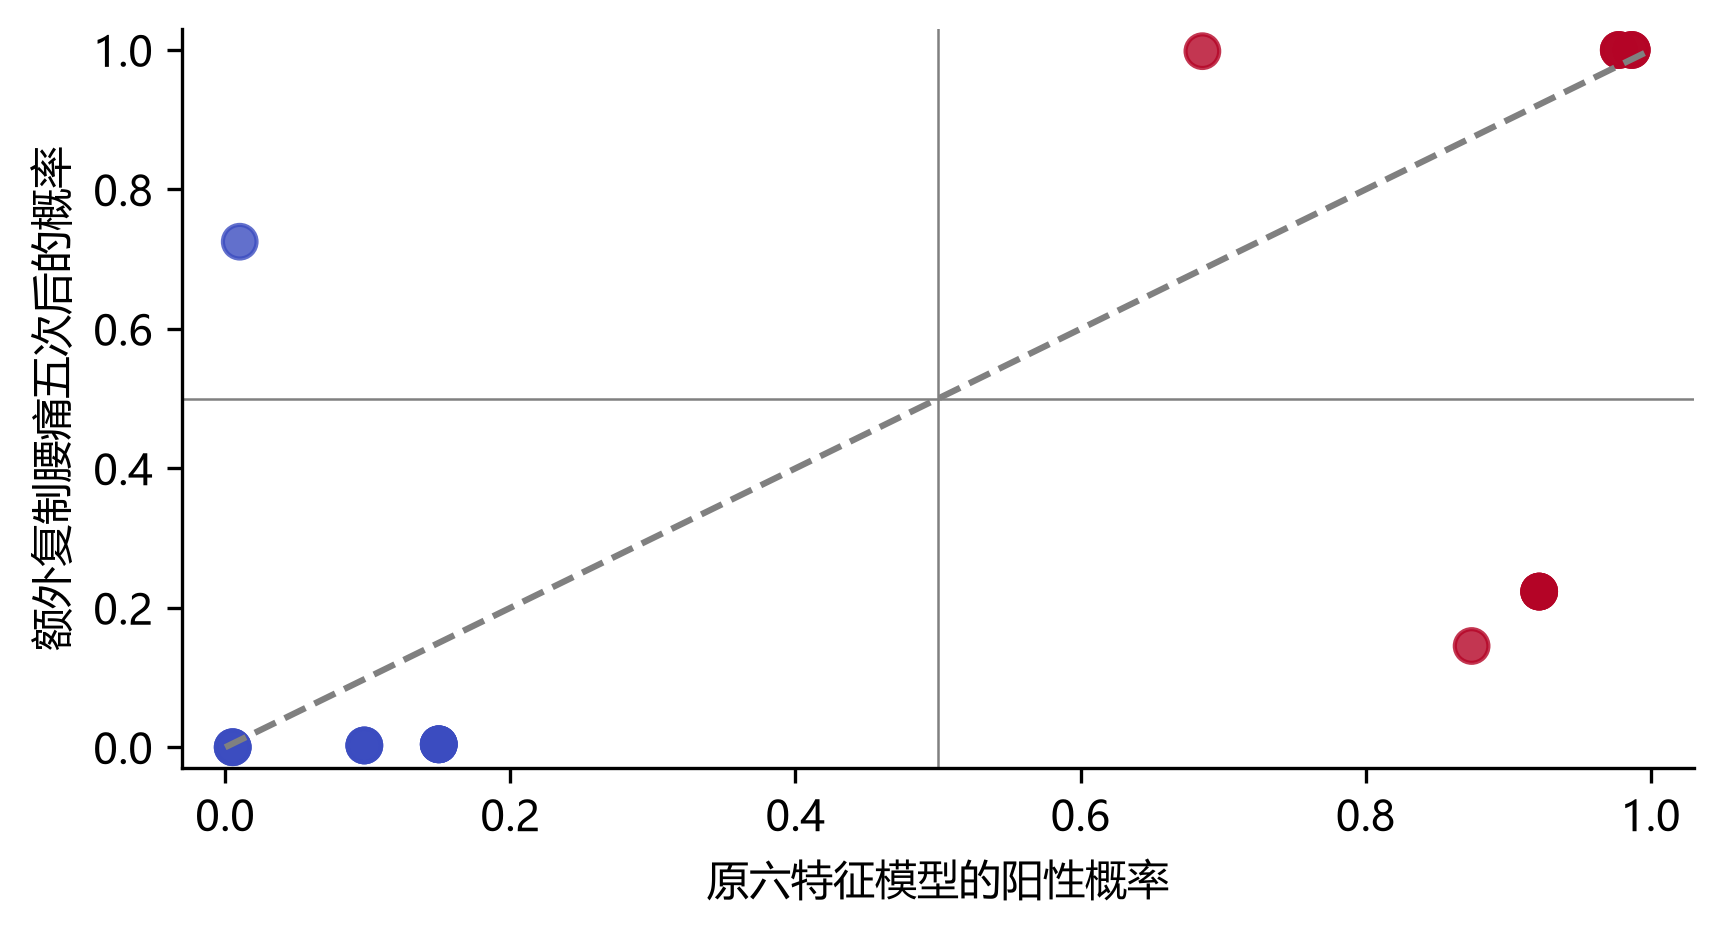

### 图4（由build.py生成，与上述分析同源）

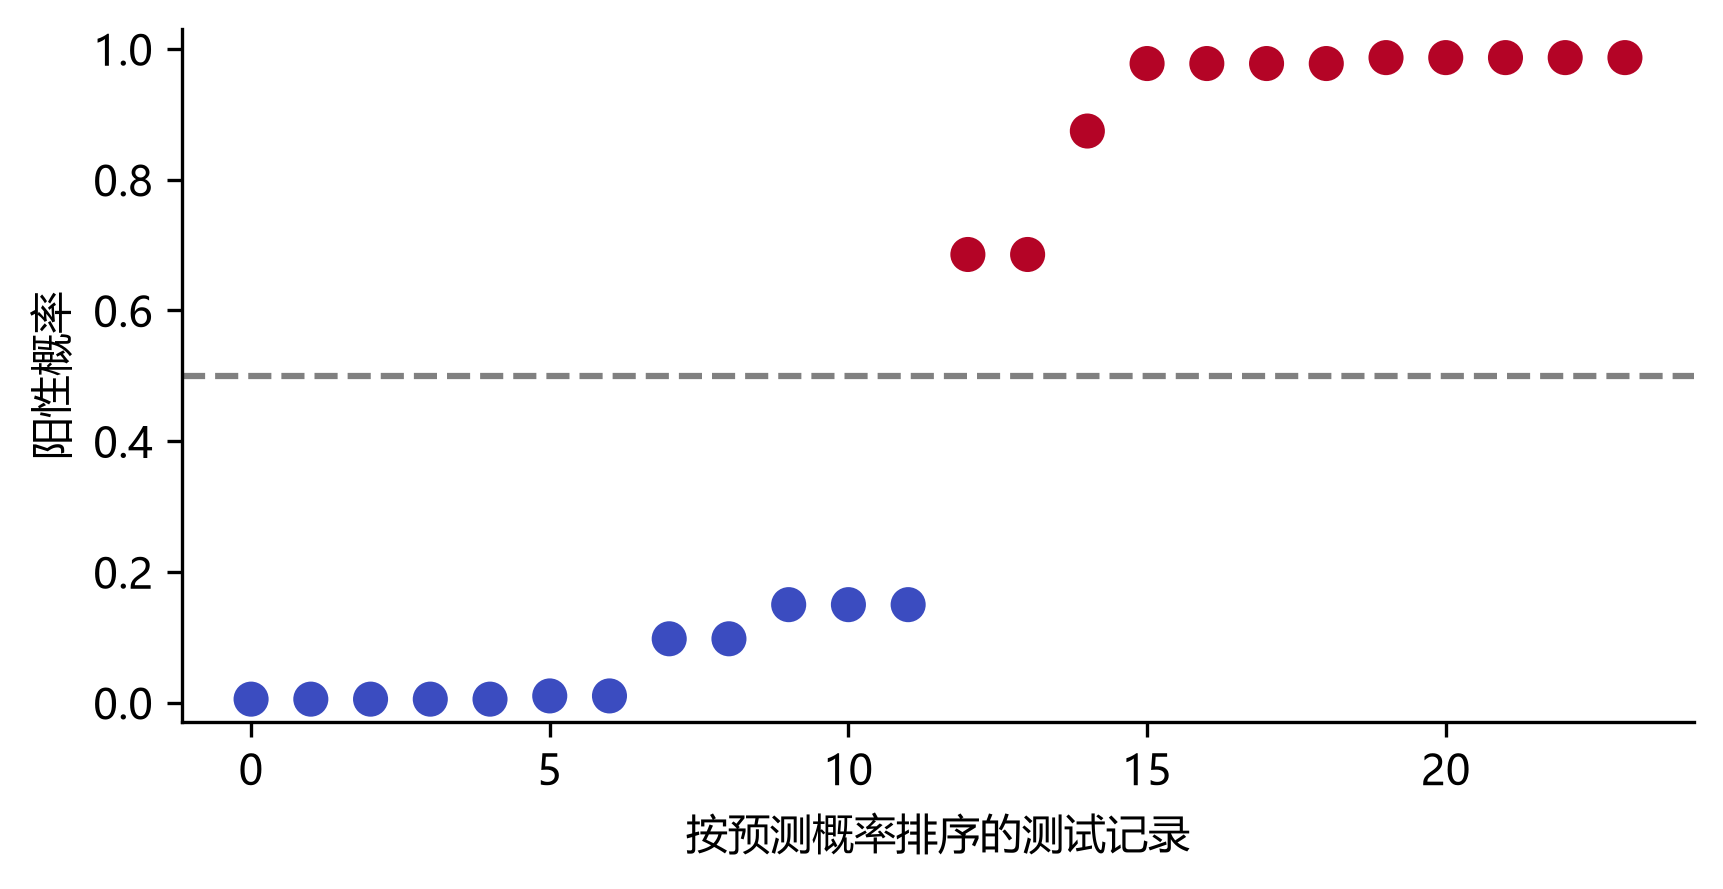